# 4. Hafta – Veri Ön İşleme (Data Preprocessing)
## Pandas ile Veri Analizi (Titanic Veri Seti)

Ham veriyi analiz ve modelleme için uygun hâle getirme işlemine **veri ön işleme** denir. Eksik, hatalı veya tutarsız veriler analiz sonuçlarını etkileyebilir.

Bu hafta:
1. Veri temizleme
2. Veri bütünleştirme
3. Veri dönüştürme
4. Veri azaltma

Önceki haftalarda kullandığımız Titanic verisi üzerinde ilerleyeceğiz. Her yöntemi ayrı bir kopyada deneyeceğiz; örneklerin tamamını art arda aynı veri setine uygulamayacağız.

**Kullanım:** Hücreleri yukarıdan aşağıya çalıştırın. Açıklamalar Markdown hücrelerindedir; kod içerisindeki `#` satırları işlemleri açıklar. Son bölümdeki alıştırmaları önce kendiniz deneyin.

## Import Library
`pandas`: tablo işlemleri; `numpy`: sayısal işlemler; `matplotlib`: grafikler; `scikit-learn`: ön işleme ve PCA.

Kütüphaneler kurulu değilse aşağıdaki hücredeki yorum işaretini kaldırabilirsiniz.

In [1]:
# %pip install pandas numpy matplotlib scikit-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler, StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

## Veriyi Yükleme
Önceki haftalarla aynı kaynak kullanılır. İnternet yoksa aynı CSV dosyasını notebook ile aynı klasöre `titanic.csv` adıyla koyabilirsiniz.

Kaynak: [pandas Titanic örnek verisi](https://github.com/pandas-dev/pandas/blob/main/doc/data/titanic.csv).

In [3]:
url = "https://raw.githubusercontent.com/pandas-dev/pandas/refs/heads/main/doc/data/titanic.csv"
try:
    df = pd.read_csv(url)
except Exception:
    df = pd.read_csv("titanic.csv")

# Ham veriyi koruyalım.
df_raw = df.copy()
display(df.head())
print("Satır ve sütun sayısı:", df.shape)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Satır ve sütun sayısı: (891, 12)


## DataFrame'i Tanıma
`Survived`: hedef değişken (0: hayatta kalmadı, 1: hayatta kaldı). `Pclass`: yolcu sınıfı; `Age`: yaş; `Fare`: bilet ücreti; `SibSp` ve `Parch`: gemideki aile üyeleri; `Embarked`: biniş limanı.

`PassengerId` bir kimliktir. Sayısal olması, bir model için anlamlı bir ölçüm olduğu anlamına gelmez.

In [4]:
df.info()
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## 1. Veri Temizleme (Data Cleaning)
Eksik değerleri, hatalı kayıtları, gürültüyü ve tekrarları inceleyerek verinin kalitesini artırırız. Her sorun aynı yöntemle çözülmez; önce sorunun kaynağı anlaşılmalıdır.

### Eksik Değerleri Tespit Etme
Eksik değer, ölçülmemiş veya kaydedilmemiş bilgidir. Pandas bu değerleri sıklıkla `NaN` olarak gösterir. **Eksik değer ile sıfır aynı şey değildir.**

Eksik oranı = Eksik kayıt sayısı / Toplam kayıt sayısı × 100.

In [5]:
eksik_ozet = pd.DataFrame({
    "Eksik Sayısı": df.isna().sum(),
    "Eksik Oranı (%)": df.isna().mean() * 100
})
eksik_ozet.sort_values("Eksik Sayısı", ascending=False)

,Eksik Sayısı,Eksik Oranı (%)
Cabin,687,77.104377
Age,177,19.865320
Embarked,2,0.224467
PassengerId,0,0.000000
Name,0,0.000000
Pclass,0,0.000000
Survived,0,0.000000
Sex,0,0.000000
Parch,0,0.000000
SibSp,0,0.000000


### Eksik Kaydı Silme: `dropna()`
Az sayıda eksik kayıt varsa ve silme önemli bilgi kaybına yol açmıyorsa kullanılabilir. Eksiklik belirli gruplarda yoğunsa silme, grupların temsilini değiştirebilir.

`subset` hangi sütunların kontrol edileceğini belirtir. `df.dropna()` tüm sütunları kontrol eder; `Cabin` gibi çok eksik bir sütun yüzünden çok sayıda yolcu kaybolabilir.

In [6]:
df_sil = df.dropna(subset=["Age"]).copy()
print("Önce:", len(df), "Sonra:", len(df_sil))
print("Silinen kayıt:", len(df) - len(df_sil))

Önce: 891 Sonra: 714
Silinen kayıt: 177


### Ortalama ile Doldurma
Ortalama, gözlenen değerlerin toplamının sayısına bölümüdür:

$$\bar{x}=\frac{1}{n}\sum_{i=1}^{n}x_i$$

Yaklaşık simetrik dağılımlarda düşünülebilir. Aykırı değerlerden etkilenir. Pandas `mean()` hesaplarken eksik değerleri dışarıda bırakır; burada $n$, gözlenen yaş sayısıdır.

Doldurma gerçek yaşı öğrenmek değildir; bir tahmindir. Aynı değerle doldurma değişkenliği azaltabilir.

In [7]:
df_ortalama = df.copy()
yas_ortalama = df["Age"].mean()
df_ortalama["Age"] = df_ortalama["Age"].fillna(yas_ortalama)
print("Kullanılan ortalama:", round(yas_ortalama, 2))
print("Kalan eksik yaş:", df_ortalama["Age"].isna().sum())

Kullanılan ortalama: 29.7
Kalan eksik yaş: 0


### Medyan ile Doldurma
Medyan, sıralanmış değerlerin ortasındaki değerdir. Gözlem sayısı çiftse ortadaki iki değerin ortalamasıdır. Aykırı değerlerden ortalamaya göre daha az etkilenir.

Özellikle çarpık dağılımlarda tercih edilebilir.

In [8]:
df_medyan = df.copy()
df_medyan["Age"] = df_medyan["Age"].fillna(df["Age"].median())


pd.DataFrame({
    "Ham": df["Age"].describe(),
    "Ortalama ile": df_ortalama["Age"].describe(),
    "Medyan ile": df_medyan["Age"].describe()})

,Ham,Ortalama ile,Medyan ile
count,714.000000,891.000000,891.000000
mean,29.699118,29.699118,29.361582
std,14.526497,13.002015,13.019697
min,0.420000,0.420000,0.420000
25%,20.125000,22.000000,22.000000
50%,28.000000,29.699118,28.000000
75%,38.000000,35.000000,35.000000
max,80.000000,80.000000,80.000000


### Kategorik Eksik Değer: Mod veya “Bilinmiyor”
Mod, en sık görülen değerdir. Kategoriler için aritmetik ortalama kullanılamaz. `Embarked` sütununu modla doldurabiliriz. `Cabin` için “Bilinmiyor” kategorisi oluşturmak da bir seçenektir.

In [9]:
df_kategori = df.copy()
liman_mod = df["Embarked"].mode().iloc[0]
df_kategori["Embarked"] = df_kategori["Embarked"].fillna(liman_mod)


df_kategori["Cabin"] = df_kategori["Cabin"].fillna("Bilinmiyor")
print("Liman modu:", liman_mod)
display(df_kategori[["Embarked", "Cabin"]].head())

Liman modu: S


,Embarked,Cabin
0,S,Bilinmiyor
1,C,C85
2,S,Bilinmiyor
3,S,C123
4,S,Bilinmiyor


### Gruplara Göre Doldurma
Tüm yolcular yerine benzer grupların medyanı kullanılabilir. Önceki haftadaki `groupby + transform` işlemi her satıra kendi grubunun değerini taşır.

Burada cinsiyet ve yolcu sınıfına göre yaş medyanı kullanıyoruz. Bir grubun bütün yaşları eksikse genel medyan yedek olarak kullanılır.

In [10]:
df_grup = df.copy()
grup_medyan = df.groupby(["Sex", "Pclass"])["Age"].transform("median")
df_grup["Age"] = df["Age"].fillna(grup_medyan).fillna(df["Age"].median())
display(df_grup.loc[df["Age"].isna(), ["Sex", "Pclass", "Age"]].head())

,Sex,Pclass,Age
5,male,3,25.0
17,male,2,30.0
19,female,3,21.5
26,male,3,25.0
28,female,3,21.5


### Regresyon ile Eksik Değer Tamamlama
Yaşı bilinen yolculardan yaş ile diğer özellikler arasındaki ilişki öğrenilir. Ardından yaşı eksik yolcular için tahmin yapılır.

$$\widehat{Age}=\beta_0+\beta_1 Pclass+\beta_2 Fare+\beta_3 SibSp+\beta_4 Parch$$

$\beta_0$ sabit terim, diğer $\beta$ değerleri modelin öğrendiği katsayılardır. `Survived` hedefini yaş tamamlama için kullanmıyoruz.

Bu basit örnek yöntemi öğretir; doğruluğu garanti etmez. Doğrulama için bilinen yaşların bir bölümü gizlenip tahmin hatası ölçülebilir. Tahminler mantıklı aralıklarda olmalı; regresyon gerçekte olmayan negatif yaşlar üretebilir.

In [11]:
df_reg = df.copy()
kolonlar = ["Pclass", "Fare", "SibSp", "Parch"]
yasi_bilinen = df["Age"].notna()
yasi_eksik = df["Age"].isna()

# Tahmin girdileri de eksik olabileceği için yalnızca bilinen yaş grubundan medyan öğrenilir.
girdi_doldurucu = SimpleImputer(strategy="median")
X_bilinen = girdi_doldurucu.fit_transform(df.loc[yasi_bilinen, kolonlar])
X_eksik = girdi_doldurucu.transform(df.loc[yasi_eksik, kolonlar])

reg_model = LinearRegression()
reg_model.fit(X_bilinen, df.loc[yasi_bilinen, "Age"])
tahmin = reg_model.predict(X_eksik)
print("Ham tahmin aralığı:", tahmin.min(), tahmin.max())

# 0–100, bu ders örneği için seçilen yaş sınırlarıdır.
df_reg.loc[yasi_eksik, "Age"] = np.clip(tahmin, 0, 100)
display(df_reg.loc[yasi_eksik, ["Pclass", "Fare", "Age"]].head())

Ham tahmin aralığı: -6.700118205339017 41.24647306955349


,Pclass,Fare,Age
5,3,8.4583,27.525206
17,2,13.0000,34.211637
19,3,7.2250,27.549701
26,3,7.2250,27.549701
28,3,7.8792,27.536708


### Hangi Doldurma Yöntemi?

| Yöntem | Ne zaman düşünülebilir? | Dikkat |
|---|---|---|
| Kaydı silme | Eksiklik az ve kayıt kaybı kabul edilebilir | Temsil ve bilgi kaybı |
| Ortalama | Yaklaşık simetrik sayısal dağılım | Aykırılardan etkilenir |
| Medyan | Çarpık veya aykırılı sayısal dağılım | Değişkenliği azaltabilir |
| Mod / Bilinmiyor | Kategorik sütun | Kategori dağılımını değiştirir |
| Grup medyanı | Anlamlı alt gruplar varsa | Küçük gruplar güvenilir olmayabilir |
| Regresyon | Diğer özellikler eksik değişkenle ilişkiliyse | Tahmin hatası ve ek model ihtiyacı |

Modelleme yaparken bu değerler **yalnızca eğitim verisinden** öğrenilir. Son bölümde bu ayrımı uygulayacağız.

### Gürültülü Veri ile Aykırı Değer Arasındaki Fark
**Gürültü:** Ölçüm veya kayıt sürecinden gelen istenmeyen değişim. **Aykırı değer:** Diğer gözlemlerden belirgin biçimde farklı bir değer.

Aykırı değer doğru olabilir: çok pahalı bir bilet gerçekten satın alınmış olabilir. Gürültü her zaman aykırı görünmez. Önce kayıt ve ölçüm koşullarını incelemek gerekir.

Titanic bir zaman serisi değildir. Rastgele yolcu sırasına hareketli ortalama uygulamak anlamlı bir gürültü giderme işlemi olmaz. Aşağıda kasıtlı eklediğimiz geçersiz bir yaşı temizliyoruz.

In [12]:
df_hata = df.copy()
df_hata.loc[0, "Age"] = -5  # Öğretim amacıyla oluşturulan hatalı kayıt
gecersiz_yas = (df_hata["Age"] < 0) | (df_hata["Age"] > 100)
display(df_hata.loc[gecersiz_yas, ["PassengerId", "Age"]])
df_hata.loc[gecersiz_yas, "Age"] = np.nan
df_hata["Age"] = df_hata["Age"].fillna(df_hata["Age"].median())

,PassengerId,Age
0,1,-5.0


### Aykırı Değer Tespiti: IQR
$Q_1$: %25 yüzdelik, $Q_3$: %75 yüzdelik. Çeyrekler arası açıklık:

$$IQR=Q_3-Q_1$$
$$Alt\ sınır=Q_1-1.5\,IQR,\quad Üst\ sınır=Q_3+1.5\,IQR$$

Sınırların dışındaki değerler inceleme için işaretlenir. 1.5 katsayısı yaygın bir kuraldır; otomatik silme zorunluluğu değildir. `Fare` dağılımını inceleyelim.

Alt ve üst sınır: -26.724 65.6344
İşaretlenen kayıt: 116


,PassengerId,Pclass,Fare
1,2,1,71.2833
27,28,1,263.0000
31,32,1,146.5208
34,35,1,82.1708
52,53,1,76.7292


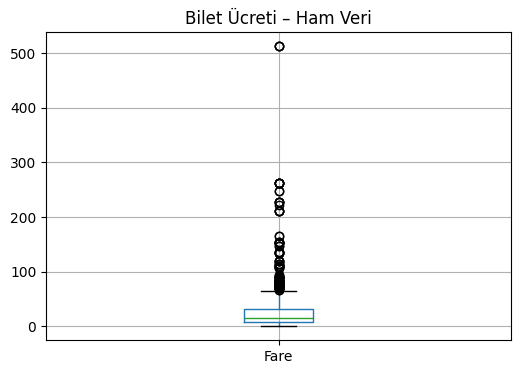

In [13]:
Q1 = df["Fare"].quantile(0.25)
Q3 = df["Fare"].quantile(0.75)
IQR = Q3 - Q1
alt_sinir = Q1 - 1.5 * IQR
ust_sinir = Q3 + 1.5 * IQR
aykiri = (df["Fare"] < alt_sinir) | (df["Fare"] > ust_sinir)
print("Alt ve üst sınır:", alt_sinir, ust_sinir)
print("İşaretlenen kayıt:", aykiri.sum())
display(df.loc[aykiri, ["PassengerId", "Pclass", "Fare"]].head())
df.boxplot(column="Fare", figsize=(6, 4))
plt.title("Bilet Ücreti – Ham Veri")
plt.show()

### Aykırı Kaydı Silme veya Sınırlandırma
**Silme:** İşaretli yolcuları çıkarır; veri kaybına yol açar.

**Sınırlandırma (`clip`):** Sınır dışı değerleri en yakın sınıra taşır; kayıt sayısı korunur fakat gerçek değer değişir.

Aşağıdaki işlemler alternatif örneklerdir. Pahalı biletleri veri hatası kabul ederek otomatik silmiyoruz.

In [14]:
df_aykiri_sil = df.loc[~aykiri].copy()
df_clip = df.copy()
df_clip["Fare"] = df_clip["Fare"].clip(lower=alt_sinir, upper=ust_sinir)
print("Ham kayıt:", len(df), "Silme sonrası:", len(df_aykiri_sil))
display(pd.DataFrame({"Ham Fare": df["Fare"], "Sınırlandırılmış Fare": df_clip["Fare"]}).loc[aykiri].head())

Ham kayıt: 891 Silme sonrası: 775


,Ham Fare,Sınırlandırılmış Fare
1,71.2833,65.6344
27,263.0000,65.6344
31,146.5208,65.6344
34,82.1708,65.6344
52,76.7292,65.6344


### Z-Score ile Aykırı Değer Tespiti
$$z_i=\frac{x_i-\mu}{\sigma}$$

$\mu$ ortalama, $\sigma$ standart sapmadır. Yaklaşık normal dağılımda $|z|>3$ inceleme için kullanılabilir. Çarpık dağılımlarda bu kural yanıltıcı olabilir. Standart sapma sıfırsa z-skor hesaplanamaz.

Aykırı değer tespiti için z-skor kullanmak ile model girdilerini standardize etmek farklı amaçlardır.

In [15]:
yas = df["Age"]
z_yas = (yas - yas.mean()) / yas.std(ddof=0)
display(df.loc[z_yas.abs() > 3, ["PassengerId", "Age"]])
print("Z-score ile işaretlenen yaş:", (z_yas.abs() > 3).sum())

,PassengerId,Age
630,631,80.0
851,852,74.0


Z-score ile işaretlenen yaş: 2


### Yinelenen (Duplicate) Kayıtlar
`duplicated()` tekrarları işaretler; `drop_duplicates()` siler. Aynı yaş ve cinsiyete sahip farklı yolcular tekrar değildir. Tekrar tanımı, kayıt kimliği ve veri kaynağına göre yapılmalıdır.

Örneğin ilk üç satırı bilinçli olarak tekrar ekleyelim.

In [16]:
df_tekrar = pd.concat([df, df.head(3)], ignore_index=True)
print("Tam satır tekrarı:", df_tekrar.duplicated().sum())
display(df_tekrar.loc[df_tekrar.duplicated(keep=False)].head(6))
df_tekil = df_tekrar.drop_duplicates().copy()
print("Önce:", len(df_tekrar), "Sonra:", len(df_tekil))

Tam satır tekrarı: 3


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
891,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
892,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
893,3,1,3,"Heikkinen, Miss Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


Önce: 894 Sonra: 891


### Anahtar Sütuna Göre Tekrar
`PassengerId` bu veri setinde yolcu kimliğidir. `subset` ile sadece bu kimliğe bakabiliriz. Aynı kimlikte farklı bilgiler varsa hangi kaydın doğru olduğu araştırılmalıdır; `keep="first"` ilk kaydı tutar, doğruluğunu garanti etmez.

In [17]:
print("Kimlik tekrarı:", df_tekrar.duplicated(subset=["PassengerId"]).sum())
df_id_tekil = df_tekrar.drop_duplicates(subset=["PassengerId"], keep="first")

Kimlik tekrarı: 3


## 2. Veri Bütünleştirme (Data Integration)
Farklı dosya veya kaynaklardaki bilgiler birleştirilir. Önce sütun adları, veri tipleri, birimler ve kategoriler uyumlu hâle getirilmelidir.

Aşağıdaki ek tablo **öğretim için oluşturulmuştur**; Titanic kaynağında bulunan ayrı bir dosya değildir.

### Şema ve Kategori Tutarsızlıkları
Şema, tablonun sütun adlarını ve veri tiplerini tanımlar. Bir kaynak `PassengerId`, diğeri `Yolcu_No` kullanabilir. Aynı bilgi `male`, `Male` veya `Erkek` şeklinde kaydedilebilir.

Birimler de kontrol edilmelidir: ay olarak tutulan yaş yıl cinsine çevrilmeden birleştirilmemelidir.

In [18]:
ek_bilgi = pd.DataFrame({
    "Yolcu_No": ["1", "2", "3"],
    "Cinsiyet": [" Erkek ", "KADIN", "kadın"],
    "Yas_Ay": [264, 456, 312],
    "Kaynak": ["Arşiv B"] * 3
})
ek_bilgi = ek_bilgi.rename(columns={"Yolcu_No": "PassengerId"})
ek_bilgi["PassengerId"] = pd.to_numeric(ek_bilgi["PassengerId"], errors="raise")
ek_bilgi["Sex_ek"] = ek_bilgi["Cinsiyet"].str.strip().str.lower().replace({"erkek": "male", "kadın": "female"})
ek_bilgi["Age_ek"] = ek_bilgi["Yas_Ay"] / 12
display(ek_bilgi)

,PassengerId,Cinsiyet,Yas_Ay,Kaynak,Sex_ek,Age_ek
0,1,Erkek,264,Arşiv B,male,22.0
1,2,KADIN,456,Arşiv B,kadin,38.0
2,3,kadın,312,Arşiv B,female,26.0


### `Merge`: Ortak Anahtarla Eşleştirme
`left`: sol tablonun tüm kayıtları; `right`: sağın tüm kayıtları; `inner`: ortak anahtarlar; `outer`: her iki tablonun tüm anahtarları.

`validate="one_to_one"` her iki tabloda anahtarın tekil olmasını denetler. Tekrarlayan anahtarlar kontrolsüz biçimde satır sayısını artırabilir. `indicator=True` eşleşmenin kaynağını gösterir.

In [19]:
df_birlesik = pd.merge(
    df, ek_bilgi[["PassengerId", "Sex_ek", "Age_ek", "Kaynak"]],
    on="PassengerId", how="left", validate="one_to_one", indicator=True
)
display(df_birlesik.head())
display(df_birlesik["_merge"].value_counts())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Sex_ek,Age_ek,Kaynak,_merge
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,male,22.0,Arşiv B,both
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,kadin,38.0,Arşiv B,both
2,3,1,3,"Heikkinen, Miss Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,female,26.0,Arşiv B,both
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,NaN,NaN,NaN,left_only
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,NaN,NaN,NaN,left_only


,count
_merge,
left_only,888
both,3
right_only,0


### Aynı Bilgide Çelişki Var mı?
İki kaynakta yaş veya cinsiyet varsa, eşleşen kayıtlar karşılaştırılır. Çelişkide kaynağın tarihi ve güvenilirliği incelenir; rastgele bir sütun seçilmez.

In [20]:
ikisi_de_var = df_birlesik["Age"].notna() & df_birlesik["Age_ek"].notna()
yas_celiski = ikisi_de_var & ~np.isclose(df_birlesik["Age"], df_birlesik["Age_ek"], equal_nan=True)
print("Yaş çelişkisi:", yas_celiski.sum())
display(df_birlesik.loc[yas_celiski, ["PassengerId", "Age", "Age_ek"]])

Yaş çelişkisi: 0


,PassengerId,Age,Age_ek


### `Concat`: Alt Alta Birleştirme
Aynı yapıya sahip kayıt gruplarını alt alta eklemek için `axis=0` kullanılır. Sütun adları aynı olmalıdır; farklı adlar ek sütun ve eksik değer oluşturabilir.

In [21]:
kaynak_A = df.iloc[:400].copy()
kaynak_B = df.iloc[400:].copy()
df_concat = pd.concat([kaynak_A, kaynak_B], axis=0, ignore_index=True)
print("Birleşen veri boyutu:", df_concat.shape)

Birleşen veri boyutu: (891, 12)


### `Join`: İndekse Göre Birleştirme
`join()` varsayılan olarak indeksleri eşleştirir. İndekslerin doğru yolcu kimliğini temsil etmesi gerekir. `concat(axis=1)` ise sütunları indeks etiketlerine göre yan yana hizalar; yolcu anahtarını kendiliğinden kontrol etmez.

In [22]:
sol = df.set_index("PassengerId")
sag = ek_bilgi.set_index("PassengerId")[["Kaynak"]]
df_join = sol.join(sag, how="left", validate="one_to_one")
display(df_join.head())

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Kaynak
PassengerId,,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Arşiv B
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Arşiv B
3,1,3,"Heikkinen, Miss Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Arşiv B
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,NaN
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,NaN


## 3. Veri Dönüştürme (Data Transformation)
Veriler analiz ve algoritmaların kullanabileceği biçime çevrilir. Ölçekleme sayısal aralıkları düzenler; kodlama kategorileri sayısal gösterime dönüştürür.

Ölçekleme özellikle uzaklık kullanan yöntemlerde ve PCA'da önemlidir. Her algoritma aynı ölçüde ölçeklemeye ihtiyaç duymaz.

### Ölçekleme Öncesi Örnek Veri
Öğretim örneklerinde yaşı medyan, limanı mod ile dolduruyoruz. Bu bölüm bütün veri üzerindeki dönüşümü tanımak içindir; modelleme için eğitim/test ayrımına son bölümde geçeceğiz.

In [23]:
df_donusum = df.copy()
df_donusum["Age"] = df_donusum["Age"].fillna(df["Age"].median())
df_donusum["Fare"] = df_donusum["Fare"].fillna(df["Fare"].median())
df_donusum["Embarked"] = df_donusum["Embarked"].fillna(df["Embarked"].mode().iloc[0])
sayisal = df_donusum[["Age", "Fare"]].copy()
display(sayisal.head())

,Age,Fare
0,22.0,7.2500
1,38.0,71.2833
2,26.0,7.9250
3,35.0,53.1000
4,35.0,8.0500


### Min-Max Normalleştirme
$$x_i'=\frac{x_i-x_{min}}{x_{max}-x_{min}}$$

Öğrenilen veri aralığı `[0, 1]` aralığına taşınır. `feature_range` ile başka aralık seçilebilir. Aykırı uçlar diğer değerleri dar bir aralığa sıkıştırabilir.

Yeni veriler eğitim minimumunun altında veya maksimumunun üzerinde olabilir; bu durumda dönüşüm `[0, 1]` dışına çıkabilir. Sabit sütunlarda payda sıfır olur; `MinMaxScaler` bunu kendisi yönetir.

In [24]:
minmax = MinMaxScaler()
minmax_df = pd.DataFrame(minmax.fit_transform(sayisal), columns=["Age_MinMax", "Fare_MinMax"], index=sayisal.index)
display(pd.concat([sayisal, minmax_df], axis=1).head())
display(minmax_df.agg(["min", "max"]))

,Age,Fare,Age_MinMax,Fare_MinMax
0,22.0,7.2500,0.271174,0.014151
1,38.0,71.2833,0.472229,0.139136
2,26.0,7.9250,0.321438,0.015469
3,35.0,53.1000,0.434531,0.103644
4,35.0,8.0500,0.434531,0.015713


,Age_MinMax,Fare_MinMax
min,0.0,0.0
max,1.0,1.0


### Z-Score Standardizasyonu
$$z_i=\frac{x_i-\mu}{\sigma}$$

Her sütunun ortalaması yaklaşık 0, standart sapması yaklaşık 1 olur. Belirli bir minimum–maksimum aralığı yoktur. **Standardizasyon veriyi normal dağılıma dönüştürmez.**

`StandardScaler` standart sapma için `ddof=0` kullanır. Pandas `std()` varsayılan olarak `ddof=1` kullandığından aşağıda `std(ddof=0)` yazıyoruz.

In [25]:
standart = StandardScaler()
standart_df = pd.DataFrame(standart.fit_transform(sayisal), columns=["Age_Z", "Fare_Z"], index=sayisal.index)
display(pd.concat([sayisal, standart_df], axis=1).head())
print("Ortalamalar:")
print(standart_df.mean().round(6))
print("Standart sapmalar:")
print(standart_df.std(ddof=0).round(6))

,Age,Fare,Age_Z,Fare_Z
0,22.0,7.2500,-0.565736,-0.502445
1,38.0,71.2833,0.663861,0.786845
2,26.0,7.9250,-0.258337,-0.488854
3,35.0,53.1000,0.433312,0.420730
4,35.0,8.0500,0.433312,-0.486337


Ortalamalar:
Age_Z     0.0
Fare_Z    0.0
dtype: float64
Standart sapmalar:
Age_Z     1.0
Fare_Z    1.0
dtype: float64


### Kategorik Veri Kodlama (Encoding)
**Nominal:** Doğal sıra yoktur (`Embarked` gibi). **Ordinal:** Sıra vardır (düşük–orta–yüksek gibi).

Kategoriye sayı vermek o kategorilerin sayısal uzaklıklarını anlamlı yapmaz. Bu nedenle kodlama seçimi değişkenin yapısına bağlıdır.

### Label Encoding
Her kategoriye bir tam sayı atanır. `LabelEncoder` esas olarak **hedef etiketlerini (`y`) kodlamak** için tasarlanmıştır. Aşağıdaki kullanım mekanizmayı öğretir.

Nominal girdi sütunlarında 0, 1, 2 gibi değerler yanlış bir sıralama izlenimi verebilir. Titanic `Survived` hedefi zaten 0/1 biçimindedir.

In [26]:

from sklearn.preprocessing import LabelEncoder
etiketleyici = LabelEncoder()
liman_kodu = etiketleyici.fit_transform(df_donusum["Embarked"])


In [27]:
etiketleyici = LabelEncoder()
liman_kodu = etiketleyici.fit_transform(df_donusum["Embarked"])
display(pd.DataFrame({"Embarked": df_donusum["Embarked"], "Liman_Kodu": liman_kodu}).head())
print("Eşleştirme:", dict(zip(etiketleyici.classes_, etiketleyici.transform(etiketleyici.classes_))))

,Embarked,Liman_Kodu
0,S,2
1,C,0
2,S,2
3,S,2
4,S,2


Eşleştirme: {'C': np.int64(0), 'Q': np.int64(1), 'S': np.int64(2)}


### Sırası Bilinen Kategoriyi Kodlama
Sıralı bir kategori için sıra açıkça tanımlanmalıdır. `Pclass` zaten 1, 2, 3 olarak kayıtlıdır; sınıflar arasındaki ekonomik farkların eşit olduğu anlamına gelmez. Algoritmaya göre One-Hot gösterimi de tercih edilebilir.

Aşağıdaki yapay örnekte sıra `Düşük < Orta < Yüksek` olarak belirlenmiştir.

In [28]:
risk = pd.Series(["Düşük", "Yüksek", "Orta", "Düşük"])
risk_kodu = risk.map({"Düşük": 0, "Orta": 1, "Yüksek": 2})
display(pd.DataFrame({"Risk": risk, "Kod": risk_kodu}))

,Risk,Kod
0,Düşük,0
1,Yüksek,2
2,Orta,1
3,Düşük,0


### One-Hot Encoding: `get_dummies()`
Her kategori ayrı bir sütun olur. İlgili kategori için 1, diğerleri için 0 yazılır. Böylece limanlar arasında yapay bir büyüklük sırası oluşturulmaz.

Kategori sayısı çok yüksekse sütun sayısı artar. `drop_first=True` bir referans kategoriyi çıkarır; özellikle sabit terimli doğrusal modellerde tam doğrusal bağımlılığı önlemek için kullanılabilir.

In [29]:
df_onehot = pd.get_dummies(df_donusum, columns=["Sex", "Embarked"], dtype=int)
display(df_onehot.filter(regex="^(Sex_|Embarked_)").head())
print("Önce:", df_donusum.shape, "Sonra:", df_onehot.shape)

,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,0,1,0,0,1
1,1,0,1,0,0
2,1,0,0,0,1
3,1,0,0,0,1
4,0,1,0,0,1


Önce: (891, 12) Sonra: (891, 15)


In [30]:
liman_onehot = pd.get_dummies(df_donusum["Embarked"], prefix="Liman", drop_first=True, dtype=int)
display(liman_onehot.head())

,Liman_Q,Liman_S
0,0,1
1,0,0
2,0,1
3,0,1
4,0,1


## 4. Veri Azaltma (Data Reduction)
Veri azaltma, hesaplama ve depolama yükünü düşürmeyi amaçlar.

- **Öznitelik seçimi:** Mevcut sütunların bir bölümünü tutma.
- **Boyut indirgeme:** Mevcut sütunlardan daha az sayıda yeni değişken üretme (PCA).
- **Örnekleme:** Satırların bir bölümünü seçme.

Azaltma bilgi kaybı oluşturabilir. Başarımın korunup korunmadığı ayrıca ölçülmelidir.

### Kullanılmayacak Sütunları Çıkarma
Bu dersin basit modelleme örneğinde kimlik ve serbest metin sütunlarını çıkarıyoruz. `Cabin` yüksek eksikliği nedeniyle çıkarılabilir; ancak kabin bilgisinden yeni özellik üretmek de mümkündür. Silme tek doğru çözüm değildir.

In [31]:
df_azalt = df_donusum.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])
print("Önce:", df_donusum.shape, "Sonra:", df_azalt.shape)
display(df_azalt.head())

Önce: (891, 12) Sonra: (891, 8)


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


### Satır Sayısını Azaltma: Örnekleme
`sample(frac=0.30)` satırların %30'unu seçer. `random_state` aynı örneğin yeniden elde edilmesini sağlar. Küçük örnekler nadir grupları yeterince temsil etmeyebilir.

Bu örnek eğitim/test ayırma işlemi değildir; hacmi azaltmayı gösterir.

In [32]:
df_ornek = df.sample(frac=0.30, random_state=42)
print("Ham:", df.shape, "Örnek:", df_ornek.shape)
display(pd.DataFrame({"Ham sınıf oranı": df["Survived"].value_counts(normalize=True), "Örnek sınıf oranı": df_ornek["Survived"].value_counts(normalize=True)}))

Ham: (891, 12) Örnek: (267, 12)


,Ham sınıf oranı,Örnek sınıf oranı
Survived,,
0,0.616162,0.588015
1,0.383838,0.411985


### Temel Bileşen Analizi (PCA)
PCA, sayısal özellikleri yeni eksenlerle temsil eder. Birinci bileşen en çok varyansı, sonraki bileşenler önceki bileşenlere dik doğrultularda kalan varyansı açıklar.

Ölçeklenmiş girdi matrisi $Z$, seçilen bileşen yönleri $W$ ise:

$$T=ZW$$

$Z$: $n\times p$ girdi, $W$: $p\times k$ yön matrisi, $T$: $n\times k$ yeni temsil. $k<p$ ise boyut azalır.

Bir bileşen örneğin $PC_1=w_1z_{Age}+w_2z_{Fare}+\cdots+w_pz_p$ biçiminde özelliklerin ağırlıklı toplamıdır.

**PCA hedef etiketini kullanmaz.** Yüksek varyans, sınıflandırma için mutlaka yüksek fayda anlamına gelmez. Bileşenler orijinal sütunlar kadar kolay yorumlanmayabilir.

### PCA Öncesi Standardizasyon
Yaş ve ücretin birimleri farklıdır; büyük ölçekli sütunun baskın olmaması için standardize ediyoruz. `Survived` ve kimlik sütununu PCA girdisine almıyoruz.

Burada yalnızca beş sayısal özellik kullanıyoruz; kategorik kodlama ayrı bölümde gösterildi.

In [33]:
pca_kolonlar = ["Age", "Fare", "SibSp", "Parch", "Pclass"]
X_pca = df_donusum[pca_kolonlar]
pca_olcek = StandardScaler()
Z = pca_olcek.fit_transform(X_pca)
pca = PCA(n_components=2)
T = pca.fit_transform(Z)
pca_df = pd.DataFrame(T, columns=["PC1", "PC2"], index=df.index)
display(pca_df.head())
print("Önce:", X_pca.shape, "Sonra:", pca_df.shape)

,PC1,PC2
0,1.140660,-0.076520
1,-1.768445,0.133479
2,0.879196,-0.726606
3,-1.458103,0.071555
4,0.561252,-0.943713


Önce: (891, 5) Sonra: (891, 2)


### Açıklanan Varyans Oranı
Bir bileşenin açıkladığı varyansın toplam varyansa oranıdır:

$$r_j=\frac{\lambda_j}{\sum_{l=1}^{p}\lambda_l}$$

$\lambda_j$, ilgili bileşenin varyansıdır. İlk $k$ bileşenin kümülatif oranı $\sum_{j=1}^{k}r_j$ olur. **%95 varyans korunması, model doğruluğunun %95 olması değildir.**

Bileşen oranları: [0.33960812 0.32520788]
İki bileşenin toplam oranı: 0.6648159969553279


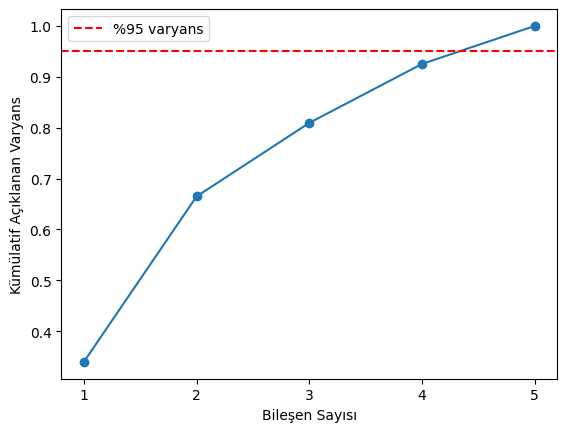

In [34]:
print("Bileşen oranları:", pca.explained_variance_ratio_)
print("İki bileşenin toplam oranı:", pca.explained_variance_ratio_.sum())
pca_tum = PCA().fit(Z)
kumulatif = np.cumsum(pca_tum.explained_variance_ratio_)
plt.plot(range(1, len(kumulatif) + 1), kumulatif, marker="o")
plt.axhline(0.95, color="red", linestyle="--", label="%95 varyans")
plt.xlabel("Bileşen Sayısı")
plt.ylabel("Kümülatif Açıklanan Varyans")
plt.xticks(range(1, len(kumulatif) + 1))
plt.legend()
plt.show()

In [35]:
# En az %95 varyansı açıklayan bileşen sayısını otomatik seçelim.
pca_95 = PCA(n_components=0.95)
T_95 = pca_95.fit_transform(Z)
print("Seçilen bileşen:", pca_95.n_components_)
print("Korunan varyans:", pca_95.explained_variance_ratio_.sum())

Seçilen bileşen: 5
Korunan varyans: 1.0


### PCA Görselleştirme
Renkler yolcuların hayatta kalma durumunu gösterir; bu etiketler PCA öğrenilirken kullanılmamıştır. Grafikte örtüşme olması, iki bileşenle kusursuz sınıf ayrımı elde edilmediğini gösterir. Grafik bir model başarım ölçümü değildir.

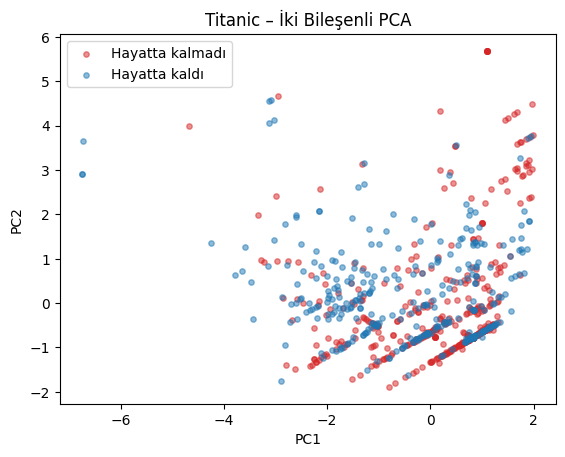

In [36]:
for durum, renk, etiket in [(0, "tab:red", "Hayatta kalmadı"), (1, "tab:blue", "Hayatta kaldı")]:
    secim = df["Survived"] == durum
    plt.scatter(pca_df.loc[secim, "PC1"], pca_df.loc[secim, "PC2"], s=15, alpha=0.5, color=renk, label=etiket)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Titanic – İki Bileşenli PCA")
plt.legend()
plt.show()

## 5. Adımları Birleştirme: Modellemeye Hazırlık
Önceki örnekler yöntemleri tek tek tanıttı. Gerçek bir tahmin çalışmasında veriyi **önce eğitim ve test olarak ayırırız**.

**Veri sızıntısı:** Test verisinden öğrenilen ortalama, medyan, ölçek veya PCA yönlerinin eğitim aşamasına taşınmasıdır. Bu, değerlendirmeyi olduğundan iyi gösterebilir.

`fit`: parametreleri öğrenir. `transform`: öğrenilmiş parametreleri uygular. Eğitimde `fit_transform`, testte yalnızca `transform` kullanılır. Test için yeniden `fit` yapılmaz.

In [37]:
X = df[["Age", "Fare", "SibSp", "Parch", "Pclass", "Sex", "Embarked"]].copy()
y = df["Survived"].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Eğitim:", X_train.shape, "Test:", X_test.shape)

Eğitim: (712, 7) Test: (179, 7)


### Sayısal Veriyi Hazırlama
Eğitim medyanıyla doldurma, ardından eğitim ortalaması ve standart sapmasıyla ölçekleme. `y_train` ön işleme girdilerine eklenmez.

In [38]:
num_cols = ["Age", "Fare", "SibSp", "Parch", "Pclass"]
num_imputer = SimpleImputer(strategy="median")
train_num = num_imputer.fit_transform(X_train[num_cols])
test_num = num_imputer.transform(X_test[num_cols])
num_scaler = StandardScaler()
train_num_z = num_scaler.fit_transform(train_num)
test_num_z = num_scaler.transform(test_num)
print("Eğitimden öğrenilen medyanlar:", num_imputer.statistics_)

Eğitimden öğrenilen medyanlar: [28.5    14.4542  0.      0.      3.    ]


### Kategorik Veriyi Hazırlama
Limanın modu yalnızca eğitim verisinden öğrenilir. One-Hot sütunları da eğitimdeki kategorilere göre belirlenir. `handle_unknown="ignore"` testte yeni bir kategori gelirse hata vermeden ilgili grubun sütunlarını sıfır yapar.

Yeni kategorilerin sıklığı ayrıca izlenmelidir. `OneHotEncoder`, eğitim/test sütunlarını kendisi aynı sırada tutar.

In [39]:
from sklearn.preprocessing import OneHotEncoder
cat_cols = ["Sex", "Embarked"]
cat_imputer = SimpleImputer(strategy="most_frequent")
train_cat = cat_imputer.fit_transform(X_train[cat_cols])
test_cat = cat_imputer.transform(X_test[cat_cols])

# Yeni ve eski scikit-learn sürümleriyle uyumluluk.
try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)
train_cat_ohe = encoder.fit_transform(train_cat)
test_cat_ohe = encoder.transform(test_cat)

feature_names = num_cols + list(encoder.get_feature_names_out(cat_cols))
X_train_ready = pd.DataFrame(np.column_stack([train_num_z, train_cat_ohe]), columns=feature_names, index=X_train.index)
X_test_ready = pd.DataFrame(np.column_stack([test_num_z, test_cat_ohe]), columns=feature_names, index=X_test.index)
display(X_train_ready.head())
print("Eğitim:", X_train_ready.shape, "Test:", X_test_ready.shape)
print("Eksik değer:", X_train_ready.isna().sum().sum(), X_test_ready.isna().sum().sum())

,Age,Fare,SibSp,Parch,Pclass,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
692,-0.081135,0.513812,-0.465084,-0.466183,0.829568,0.0,1.0,0.0,0.0,1.0
481,-0.081135,-0.662563,-0.465084,-0.466183,-0.370945,0.0,1.0,0.0,0.0,1.0
527,-0.081135,3.955399,-0.465084,-0.466183,-1.571457,0.0,1.0,0.0,0.0,1.0
855,-0.887827,-0.467874,-0.465084,0.727782,0.829568,1.0,0.0,0.0,0.0,1.0
801,0.110934,-0.115977,0.478335,0.727782,-0.370945,1.0,0.0,0.0,0.0,1.0


Eğitim: (712, 10) Test: (179, 10)
Eksik değer: 0 0


### Eğitimden Öğrenilen PCA'yı Teste Uygulama
Bu örnekte PCA yalnızca beş sayısal özelliğe uygulanır; One-Hot sütunları ayrıca korunur. Böylece önceki PCA örneğinin eğitim/test sürümünü görürüz.

Azaltılmış girdilerin model başarımını koruyup korumadığını ilerleyen haftalarda aynı eğitim/test ayrımında karşılaştıracağız. Burada sınıflandırıcı eğitmiyoruz.

In [40]:
pca_train = PCA(n_components=0.95)
train_pc = pca_train.fit_transform(train_num_z)
test_pc = pca_train.transform(test_num_z)
X_train_reduced = np.column_stack([train_pc, train_cat_ohe])
X_test_reduced = np.column_stack([test_pc, test_cat_ohe])
print("Sayısal özellik → bileşen:", len(num_cols), "→", pca_train.n_components_)
print("Azaltılmış eğitim/test:", X_train_reduced.shape, X_test_reduced.shape)

Sayısal özellik → bileşen: 5 → 5
Azaltılmış eğitim/test: (712, 10) (179, 10)


## Uygulama Soruları
1. `Age` için ortalama ve medyan ile doldurulmuş verilerin histogramlarını karşılaştırın. Doldurulan değer çevresinde ne değişiyor?
2. `Embarked` sütununda eksik kayıtları silmek ile modla doldurmak arasındaki farkı gösterin.
3. `Fare` için IQR katsayısını 1.5 yerine 3 alın. Kaç kayıt işaretleniyor?
4. İlk beş yolcuyu tekrar ekleyin. Tam satır ve kimlik tekrarlarını ayrı ayrı sayın.
5. Sınıf numarası ve sınıf açıklaması içeren küçük bir tablo oluşturup `Pclass` üzerinden `merge` yapın. Uygun `validate` değerini düşünün.
6. `Age` ve `Fare` için Min-Max ve Z-Score sonuçlarını karşılaştırın.
7. `Embarked` için Label Encoding neden yapay bir sıra oluşturabilir? One-Hot ile açıklayın.
8. PCA'da %90 ve %95 varyans hedefleri için bileşen sayılarını karşılaştırın. Bileşen sayısının mutlaka farklı olması gerekir mi?
9. Test verisine neden `fit_transform()` uygulamıyoruz?

**Not:** Her denemeye `df.copy()` ile başlayın; önceki denemenin değişikliklerini istemeden taşımayın.

In [41]:
# Alıştırmalar için kodlarınızı bu hücreye yazabilirsiniz.

## Haftanın Özeti

| İşlem | Amaç | Örnek fonksiyon |
|---|---|---|
| Eksik değer işlemleri | Eksik bilgiyi yönetme | `isna`, `fillna`, `dropna`, `SimpleImputer` |
| Hatalı / aykırı kayıt inceleme | Veri kalitesini artırma | `quantile`, `clip` |
| Tekrar kontrolü | Aynı kaydın tekrarını giderme | `duplicated`, `drop_duplicates` |
| Bütünleştirme | Kaynakları eşleştirme veya ekleme | `merge`, `concat`, `join` |
| Ölçekleme | Sayısal ölçekleri düzenleme | `MinMaxScaler`, `StandardScaler` |
| Kodlama | Kategorileri sayısal gösterme | `map`, `get_dummies`, `OneHotEncoder` |
| Azaltma | Daha küçük veri temsili | `drop`, `sample`, `PCA` |

Yöntem seçimi verinin yapısına bağlıdır. Ham veriyi koruyun, uyguladığınız işlemleri kaydedin ve modelleme aşamasında ön işleme parametrelerini yalnızca eğitim verisinden öğrenin.